In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
data_path = Path(r"C:\Users\pc\XAI-Intrusion-Detection\data\MachineLearningCVE")

csv_files = sorted(data_path.glob("*.csv"))

print("Number of CSV files:", len(csv_files))

for file in csv_files:
    print(file.name)

Number of CSV files: 8
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Friday-WorkingHours-Morning.pcap_ISCX.csv
Monday-WorkingHours.pcap_ISCX.csv
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Tuesday-WorkingHours.pcap_ISCX.csv
Wednesday-workingHours.pcap_ISCX.csv


In [3]:
df = pd.read_csv(csv_files[0], encoding="latin1")

df.columns = df.columns.str.strip()

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (225745, 79)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,54865,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,55054,109,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,55055,52,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,46236,34,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,54863,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [4]:
print("Dataset file:", csv_files[0].name)

print("\nAttack categories:")
print(df["Label"].value_counts())

print("\nPercentage distribution:")
print(df["Label"].value_counts(normalize=True) * 100)

Dataset file: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv

Attack categories:
Label
DDoS      128027
BENIGN     97718
Name: count, dtype: int64

Percentage distribution:
Label
DDoS      56.713105
BENIGN    43.286895
Name: proportion, dtype: float64


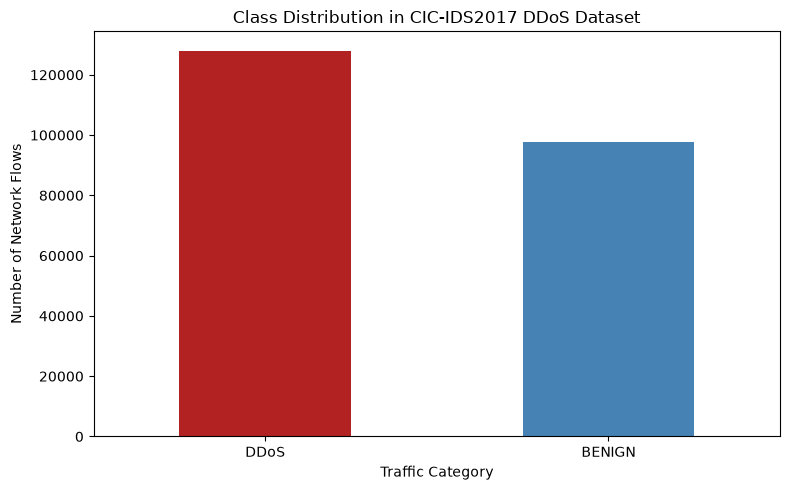

In [5]:
plt.figure(figsize=(8, 5))

df["Label"].value_counts().plot(
    kind="bar",
    color=["firebrick", "steelblue"]
)

plt.title("Class Distribution in CIC-IDS2017 DDoS Dataset")
plt.xlabel("Traffic Category")
plt.ylabel("Number of Network Flows")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("01_ddos_class_distribution.png", dpi=300)

plt.show()

In [6]:
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

print("\nMissing values:", df.isnull().sum().sum())

print("Duplicate rows:", df.duplicated().sum())

numeric_data = df.select_dtypes(include=[np.number])

print("Infinite values:", np.isinf(numeric_data).sum().sum())

print("\nColumn data types:")
print(df.dtypes.value_counts())

Total rows: 225745
Total columns: 79

Missing values: 4
Duplicate rows: 2633
Infinite values: 64

Column data types:
int64      54
float64    24
str         1
Name: count, dtype: int64


In [7]:
print("Columns with missing values:")

missing = df.isnull().sum()
print(missing[missing > 0])

print("\nColumns with infinite values:")

infinite = np.isinf(numeric_data).sum()
print(infinite[infinite > 0])

print("\nColumns with constant values:")

constant_columns = df.columns[df.nunique() <= 1]
print(constant_columns.tolist())

print("\nNumber of constant columns:", len(constant_columns))

Columns with missing values:
Flow Bytes/s    4
dtype: int64

Columns with infinite values:
Flow Bytes/s      30
Flow Packets/s    34
dtype: int64

Columns with constant values:
['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'CWE Flag Count', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']

Number of constant columns: 10


In [8]:
dataset_summary = []
all_labels = []

for file in csv_files:
    labels = pd.read_csv(
        file,
        encoding="latin1",
        usecols=lambda col: col.strip() == "Label"
    )

    labels.columns = labels.columns.str.strip()

    dataset_summary.append({
        "File": file.name,
        "Records": len(labels),
        "Categories": labels["Label"].nunique()
    })

    all_labels.append(labels["Label"])

summary_df = pd.DataFrame(dataset_summary)

print("Total network flows:", summary_df["Records"].sum())

display(summary_df)

Total network flows: 2830743


,File,Records,Categories
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,225745,2
1,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,286467,2
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,191033,2
3,Monday-WorkingHours.pcap_ISCX.csv,529918,1
4,Thursday-WorkingHours-Afternoon-Infilteration....,288602,2
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,170366,4
6,Tuesday-WorkingHours.pcap_ISCX.csv,445909,3
7,Wednesday-workingHours.pcap_ISCX.csv,692703,6


In [9]:
combined_labels = pd.concat(all_labels, ignore_index=True)

class_counts = combined_labels.value_counts()

class_percentages = combined_labels.value_counts(
    normalize=True
) * 100

class_distribution = pd.DataFrame({
    "Records": class_counts,
    "Percentage": class_percentages.round(4)
})

print("Total network flows:", len(combined_labels))
print("Number of traffic categories:", combined_labels.nunique())

display(class_distribution)

Total network flows: 2830743
Number of traffic categories: 15


,Records,Percentage
Label,,
BENIGN,2273097,80.3004
DoS Hulk,231073,8.1630
PortScan,158930,5.6144
DDoS,128027,4.5227
DoS GoldenEye,10293,0.3636
FTP-Patator,7938,0.2804
SSH-Patator,5897,0.2083
DoS slowloris,5796,0.2048
DoS Slowhttptest,5499,0.1943


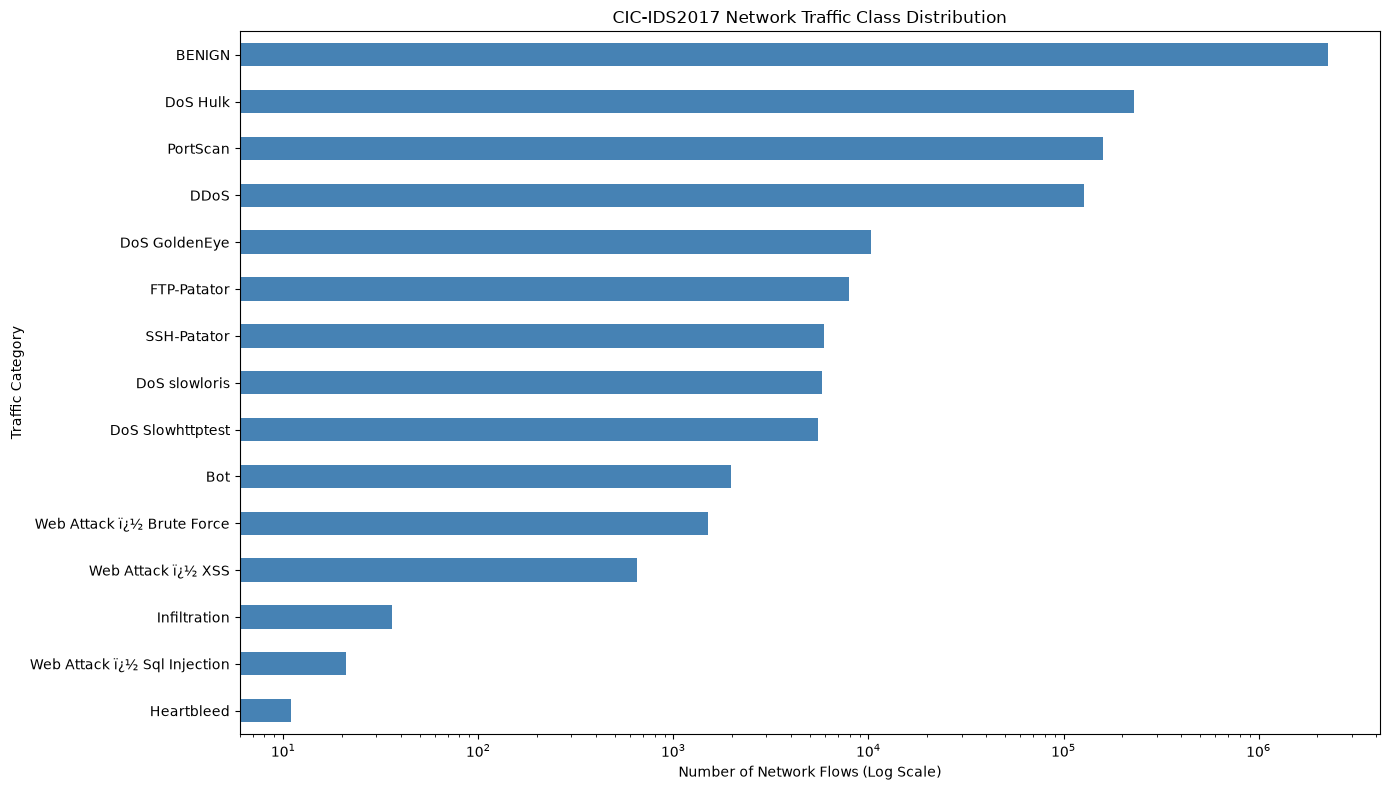

In [10]:
plt.figure(figsize=(14, 8))

class_counts.sort_values().plot(
    kind="barh",
    color="steelblue",
    logx=True
)

plt.title("CIC-IDS2017 Network Traffic Class Distribution")
plt.xlabel("Number of Network Flows (Log Scale)")
plt.ylabel("Traffic Category")
plt.tight_layout()

plt.show()

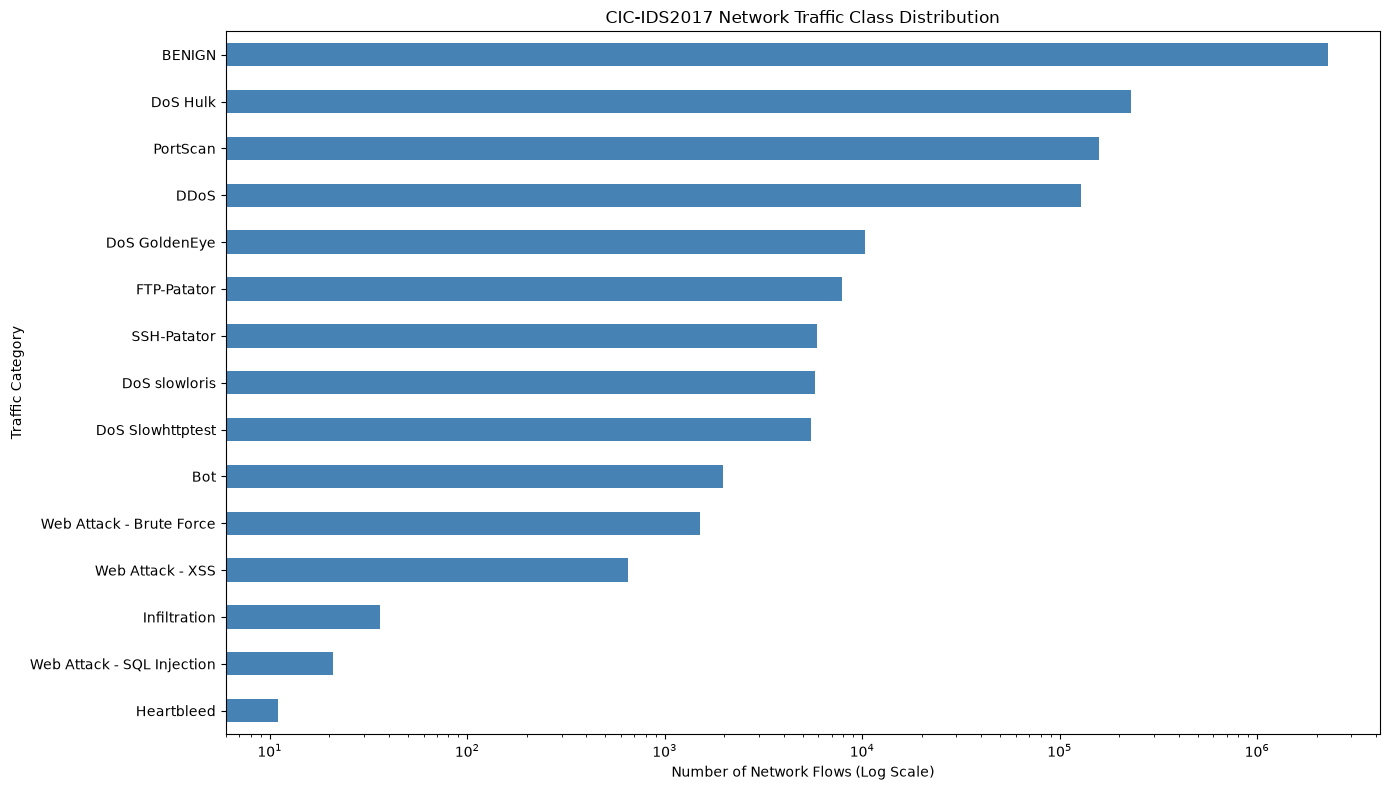

Figure saved successfully!


In [11]:
clean_labels = combined_labels.str.strip().replace(
    {
        r"^Web Attack.*Brute Force$": "Web Attack - Brute Force",
        r"^Web Attack.*XSS$": "Web Attack - XSS",
        r"^Web Attack.*Sql Injection$": "Web Attack - SQL Injection"
    },
    regex=True
)

clean_counts = clean_labels.value_counts()

results_path = data_path.parent.parent / "results"
results_path.mkdir(exist_ok=True)

plt.figure(figsize=(14, 8))

clean_counts.sort_values().plot(
    kind="barh",
    color="steelblue",
    logx=True
)

plt.title("CIC-IDS2017 Network Traffic Class Distribution")
plt.xlabel("Number of Network Flows (Log Scale)")
plt.ylabel("Traffic Category")
plt.tight_layout()

plt.savefig(
    results_path / "class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved successfully!")

In [12]:
final_distribution = pd.DataFrame({
    "Records": clean_counts,
    "Percentage": (
        clean_counts / clean_counts.sum() * 100
    ).round(4)
})

final_distribution.to_csv(
    results_path / "class_distribution.csv"
)

print("Total network flows:", clean_counts.sum())
print("Total traffic categories:", len(clean_counts))
print("Statistics saved successfully!")

display(final_distribution)

Total network flows: 2830743
Total traffic categories: 15
Statistics saved successfully!


,Records,Percentage
Label,,
BENIGN,2273097,80.3004
DoS Hulk,231073,8.1630
PortScan,158930,5.6144
DDoS,128027,4.5227
DoS GoldenEye,10293,0.3636
FTP-Patator,7938,0.2804
SSH-Patator,5897,0.2083
DoS slowloris,5796,0.2048
DoS Slowhttptest,5499,0.1943


In [13]:
import psutil

memory = psutil.virtual_memory()

print("Total RAM:", round(memory.total / (1024**3), 2), "GB")

print("Available RAM:", round(memory.available / (1024**3), 2), "GB")

print("Memory usage:", memory.percent, "%")

Total RAM: 31.69 GB
Available RAM: 22.05 GB
Memory usage: 30.4 %


In [14]:
dataframes = []

for file in csv_files:
    print("Loading:", file.name)

    temp_df = pd.read_csv(file, low_memory=False)
    temp_df.columns = temp_df.columns.str.strip()

    dataframes.append(temp_df)

full_df = pd.concat(dataframes, ignore_index=True)

del dataframes, temp_df

print("\nComplete dataset loaded successfully!")
print("Dataset shape:", full_df.shape)
print("Total records:", len(full_df))
print("Total columns:", len(full_df.columns))

print("Memory used (GB):",
      round(full_df.memory_usage(deep=True).sum() / 1024**3, 2))

Loading: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Loading: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Loading: Friday-WorkingHours-Morning.pcap_ISCX.csv
Loading: Monday-WorkingHours.pcap_ISCX.csv
Loading: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Loading: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Loading: Tuesday-WorkingHours.pcap_ISCX.csv
Loading: Wednesday-workingHours.pcap_ISCX.csv

Complete dataset loaded successfully!
Dataset shape: (2830743, 79)
Total records: 2830743
Total columns: 79
Memory used (GB): 1.79


In [15]:
print("COMPLETE DATASET QUALITY ASSESSMENT")

print("\nTotal records:", len(full_df))
print("Total columns:", len(full_df.columns))

print("\nMissing values:",
      full_df.isna().sum().sum())

print("Duplicate rows:",
      full_df.duplicated().sum())

numeric_columns = full_df.select_dtypes(
    include=[np.number]
).columns

infinite_count = sum(
    np.isinf(full_df[col]).sum()
    for col in numeric_columns
)

print("Infinite values:", infinite_count)

print("\nColumn data types:")
print(full_df.dtypes.value_counts())

print("\nTraffic categories:")
print(full_df["Label"].value_counts())

COMPLETE DATASET QUALITY ASSESSMENT

Total records: 2830743
Total columns: 79

Missing values: 1358
Duplicate rows: 308381
Infinite values: 4376

Column data types:
int64      54
float64    24
str         1
Name: count, dtype: int64

Traffic categories:
Label
BENIGN                        2273097
DoS Hulk                       231073
PortScan                       158930
DDoS                           128027
DoS GoldenEye                   10293
FTP-Patator                      7938
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1966
Web Attack � Brute Force         1507
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64


In [16]:
# Create a working copy of the original dataset
clean_df = full_df.copy()

# Remove unnecessary spaces from column names
clean_df.columns = clean_df.columns.str.strip()

# Standardize traffic labels
clean_df["Label"] = clean_df["Label"].str.strip()

# Correct malformed web attack labels
clean_df["Label"] = clean_df["Label"].str.replace(
    r"^Web Attack.*Brute Force$",
    "Web Attack - Brute Force",
    regex=True
)

clean_df["Label"] = clean_df["Label"].str.replace(
    r"^Web Attack.*XSS$",
    "Web Attack - XSS",
    regex=True
)

clean_df["Label"] = clean_df["Label"].str.replace(
    r"^Web Attack.*Sql Injection$",
    "Web Attack - SQL Injection",
    regex=True
)

print("Column names and labels cleaned successfully!")

print("\nUpdated traffic categories:")
print(clean_df["Label"].value_counts())

Column names and labels cleaned successfully!

Updated traffic categories:
Label
BENIGN                        2273097
DoS Hulk                       231073
PortScan                       158930
DDoS                           128027
DoS GoldenEye                   10293
FTP-Patator                      7938
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1966
Web Attack - Brute Force         1507
Web Attack - XSS                  652
Infiltration                       36
Web Attack - SQL Injection         21
Heartbleed                         11
Name: count, dtype: int64


In [17]:
# Record dataset size before cleaning
rows_before = len(clean_df)

# Convert infinite values to missing values
clean_df.replace([np.inf, -np.inf], np.nan, inplace=True)

# Remove rows containing missing values
clean_df.dropna(inplace=True)

# Record dataset size after cleaning
rows_after = len(clean_df)

print("Missing and infinite values handled successfully!")

print("\nRows before cleaning:", rows_before)
print("Rows after cleaning:", rows_after)
print("Rows removed:", rows_before - rows_after)

print("\nRemaining missing values:")
print(clean_df.isnull().sum().sum())

print("\nUpdated traffic categories:")
print(clean_df["Label"].value_counts())

C:\Users\pc\AppData\Local\Temp\ipykernel_2712\2841184424.py:8: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  clean_df.dropna(inplace=True)


Missing and infinite values handled successfully!

Rows before cleaning: 2830743
Rows after cleaning: 2827876
Rows removed: 2867

Remaining missing values:
0

Updated traffic categories:
Label
BENIGN                        2271320
DoS Hulk                       230124
PortScan                       158804
DDoS                           128025
DoS GoldenEye                   10293
FTP-Patator                      7935
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1956
Web Attack - Brute Force         1507
Web Attack - XSS                  652
Infiltration                       36
Web Attack - SQL Injection         21
Heartbleed                         11
Name: count, dtype: int64


In [18]:
# Record dataset size before removing duplicates
before_duplicates = len(clean_df)

# Remove exact duplicate records
clean_df = clean_df.drop_duplicates()

# Reset the dataset index
clean_df = clean_df.reset_index(drop=True)

# Record dataset size after removing duplicates
after_duplicates = len(clean_df)

print("Duplicate removal completed successfully!")

print("\nRows before:", before_duplicates)
print("Rows after:", after_duplicates)
print("Duplicates removed:", before_duplicates - after_duplicates)

print("\nRemaining duplicate rows:")
print(clean_df.duplicated().sum())

print("\nUpdated traffic categories:")
print(clean_df["Label"].value_counts())

Duplicate removal completed successfully!

Rows before: 2827876
Rows after: 2520798
Duplicates removed: 307078

Remaining duplicate rows:
0

Updated traffic categories:
Label
BENIGN                        2095057
DoS Hulk                       172846
DDoS                           128014
PortScan                        90694
DoS GoldenEye                   10286
FTP-Patator                      5931
DoS slowloris                    5385
DoS Slowhttptest                 5228
SSH-Patator                      3219
Bot                              1948
Web Attack - Brute Force         1470
Web Attack - XSS                  652
Infiltration                       36
Web Attack - SQL Injection         21
Heartbleed                         11
Name: count, dtype: int64


In [19]:
# Identify constant features in the complete dataset

constant_features = [
    col for col in clean_df.columns
    if col != "Label" and clean_df[col].nunique() <= 1
]

print("Constant features identified:")

for feature in constant_features:
    print(feature)

print("\nTotal constant features:", len(constant_features))

print("\nCurrent dataset shape:", clean_df.shape)

Constant features identified:
Bwd PSH Flags
Bwd URG Flags
Fwd Avg Bytes/Bulk
Fwd Avg Packets/Bulk
Fwd Avg Bulk Rate
Bwd Avg Bytes/Bulk
Bwd Avg Packets/Bulk
Bwd Avg Bulk Rate

Total constant features: 8

Current dataset shape: (2520798, 79)


In [20]:
# Remove constant features

before_columns = clean_df.shape[1]

clean_df = clean_df.drop(columns=constant_features)

after_columns = clean_df.shape[1]

print("Constant feature removal completed successfully!")

print("\nColumns before:", before_columns)
print("Columns after:", after_columns)
print("Features removed:", before_columns - after_columns)

print("\nUpdated dataset shape:", clean_df.shape)

print("Remaining input features:", clean_df.shape[1] - 1)

print("Target column preserved:", "Label" in clean_df.columns)


Constant feature removal completed successfully!

Columns before: 79
Columns after: 71
Features removed: 8

Updated dataset shape: (2520798, 71)
Remaining input features: 70
Target column preserved: True


In [21]:
# Final data quality verification

print("FINAL DATA QUALITY VERIFICATION")
print("-" * 45)

print("Total records:", len(clean_df))
print("Total columns:", clean_df.shape[1])

print("Missing values:", clean_df.isna().sum().sum())

print("Duplicate rows:", clean_df.duplicated().sum())

numeric_columns = clean_df.select_dtypes(
    include=[np.number]
).columns

infinite_count = sum(
    np.isinf(clean_df[col]).sum()
    for col in numeric_columns
)

print("Infinite values:", infinite_count)

print("Traffic categories:", clean_df["Label"].nunique())

print("\nFinal traffic distribution:")
print(clean_df["Label"].value_counts())

FINAL DATA QUALITY VERIFICATION
---------------------------------------------
Total records: 2520798
Total columns: 71
Missing values: 0
Duplicate rows: 0
Infinite values: 0
Traffic categories: 15

Final traffic distribution:
Label
BENIGN                        2095057
DoS Hulk                       172846
DDoS                           128014
PortScan                        90694
DoS GoldenEye                   10286
FTP-Patator                      5931
DoS slowloris                    5385
DoS Slowhttptest                 5228
SSH-Patator                      3219
Bot                              1948
Web Attack - Brute Force         1470
Web Attack - XSS                  652
Infiltration                       36
Web Attack - SQL Injection         21
Heartbleed                         11
Name: count, dtype: int64


In [22]:
%pip install pyarrow

   ---------------------------------------- 0.0/29.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/29.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/29.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/29.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/29.1 MB ? eta -:--:--
   ---------------------------------------- 0.3/29.1 MB ? eta -:--:--
   - -------------------------------------- 0.8/29.1 MB 1.6 MB/s eta 0:00:18
   - -------------------------------------- 1.0/29.1 MB 2.1 MB/s eta 0:00:14
   -- ------------------------------------- 2.1/29.1 MB 2.4 MB/s eta 0:00:12
   --- ------------------------------------ 2.6/29.1 MB 2.4 MB/s eta 0:00:11
   ---- ----------------------------------- 3.4/29.1 MB 2.7 MB/s eta 0:00:10
   ----- ---------------------------------- 4.2/29.1 MB 3.0 MB/s eta 0:00:09
   ------- -------------------------------- 5.2/29.1 MB 3.2 MB/s eta 0:00:08
   ------- ------------------------------

In [23]:
from pathlib import Path

# Create a directory for the processed dataset

processed_dir = Path("processed_data")
processed_dir.mkdir(parents=True, exist_ok=True)

# Define the output file

output_path = processed_dir / "CICIDS2017_cleaned.parquet"

# Save the cleaned dataset

clean_df.to_parquet(
    output_path,
    engine="pyarrow",
    compression="snappy",
    index=False
)

print("Cleaned dataset saved successfully!")

print("\nFile location:", output_path.resolve())

print("File size (MB):",
      round(output_path.stat().st_size / (1024**2), 2))

print("Records saved:", len(clean_df))
print("Columns saved:", clean_df.shape[1])

Cleaned dataset saved successfully!

File location: C:\Users\pc\XAI-Intrusion-Detection\processed_data\CICIDS2017_cleaned.parquet
File size (MB): 305.04
Records saved: 2520798
Columns saved: 71


In [24]:
# Verify the saved Parquet dataset

import pyarrow.parquet as pq

saved_file = pq.ParquetFile(output_path)

print("SAVED DATASET VERIFICATION")
print("-" * 40)

print("File exists:", output_path.exists())
print("Saved records:", saved_file.metadata.num_rows)
print("Saved columns:", saved_file.metadata.num_columns)

print("Target column preserved:",
      "Label" in saved_file.schema_arrow.names)

print("\nSample records:")

display(
    next(saved_file.iter_batches(batch_size=5)).to_pandas()
)

SAVED DATASET VERIFICATION
----------------------------------------
File exists: True
Saved records: 2520798
Saved columns: 71
Target column preserved: True

Sample records:


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,54865,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,55054,109,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,55055,52,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,46236,34,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,54863,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
